In [11]:
from anemone.system import Loop, Receiver
from anemone.forwards import Forward
from anemone.physics import dbdt_center_of_circular_loop_halfspace
import matplotlib.pyplot as plt

import torch

In [40]:
tx = Loop.circle(1.)
rx = Receiver()
t  = torch.logspace(-9, -2, 201)


fwr = Forward(tx, rx, t)

In [41]:
rho = torch.logspace(0., 3., 7)

In [42]:
dbdt = fwr(rho)
dbdt_analytic = dbdt_center_of_circular_loop_halfspace(t[None,:], rho[:,None], tx.radius)
dbdt_abserr = dbdt-dbdt_analytic
dbdt_relerr = torch.abs(dbdt_abserr / dbdt_analytic)*100.

Text(0.5, 0, 'time [s]')

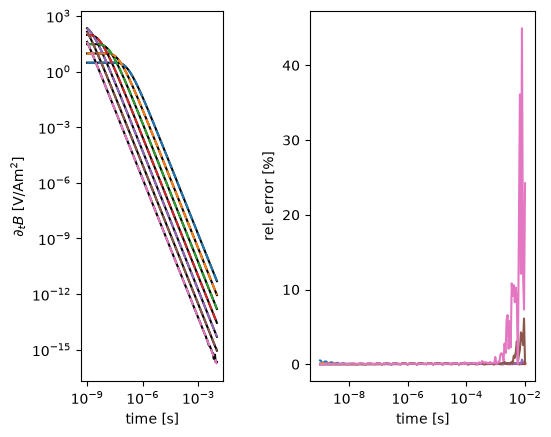

In [ ]:
fig,axs = plt.subplots(1,2)
axs[0].loglog(fwr.times, dbdt_analytic.T, 'k-')
axs[0].loglog(fwr.times, dbdt.T, '--')
axs[0].set_ylabel('$\\partial_tB$ [V/Am$^2$]')
axs[0].set_xlabel('time [s]')

axs[0].set_aspect('equal')

axs[1].semilogx(fwr.times, dbdt_relerr.T)
axs[1].set_ylabel('rel. error [%]')
axs[1].set_xlabel('time [s]')